# Telco Churn EDA

This notebook will load the Telco Customer Churn dataset, clean it, and explore churn drivers.

## Workflow
1. Load processed churn data
2. Explore churn distribution and segment-level churn rates
3. Save key EDA summary tables and figures for dashboard assets

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/processed/telco_churn_processed.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnFlag
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


In [2]:
df["TenureBucket"] = pd.cut(
    df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0-6", "7-12", "13-24", "25-48", "49-72"],
)

overview = {
    "total_customers": len(df),
    "churned_customers": int(df["ChurnFlag"].sum()),
    "churn_rate": float(df["ChurnFlag"].mean()),
}
overview

{'total_customers': 7043,
 'churned_customers': 1869,
 'churn_rate': 0.2653698707936959}

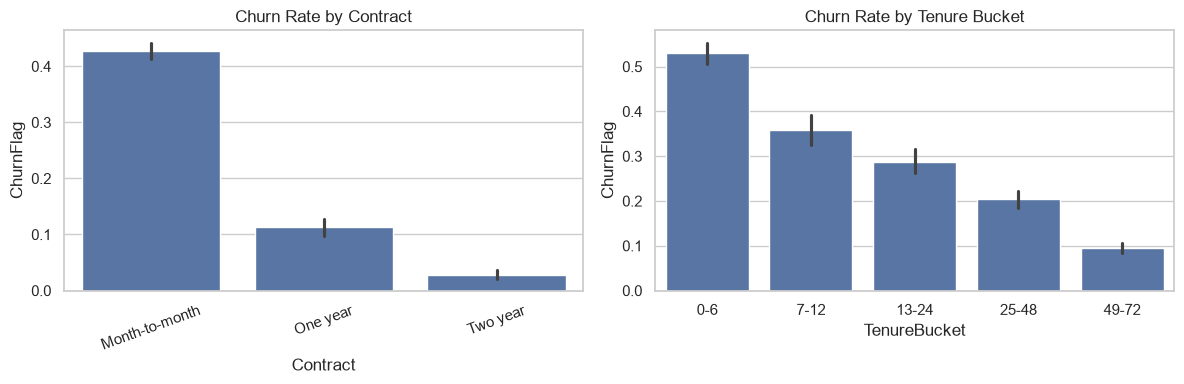

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=df, x="Contract", y="ChurnFlag", ax=axes[0])
axes[0].set_title("Churn Rate by Contract")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=df, x="TenureBucket", y="ChurnFlag", ax=axes[1])
axes[1].set_title("Churn Rate by Tenure Bucket")

plt.tight_layout()

output_dir = Path("../outputs/eda")
output_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(output_dir / "eda_notebook_contract_tenure.png", dpi=150)
plt.show()